In [2]:
from pathlib import Path

TRAIN_DIR = Path("../data/processed/tomato_potato_split/train")

print("Train directory:")
print(TRAIN_DIR.resolve())

print("\nDirectory exists:", TRAIN_DIR.exists())

# Find all files recursively
all_files = [
    f for f in TRAIN_DIR.rglob("*")
    if f.is_file()
]

print("\nTotal files found:", len(all_files))

# Show file extensions
extensions = {}

for file in all_files:
    ext = file.suffix.lower()
    extensions[ext] = extensions.get(ext, 0) + 1

print("\nFile extensions:")
for ext, count in sorted(extensions.items()):
    print(f"{ext}: {count}")

# Show a few actual files
print("\nSample files:")

for file in all_files[:10]:
    print(file)

Train directory:
C:\Users\ATHARVA\Desktop\Mini project\data\processed\tomato_potato_split\train

Directory exists: False

Total files found: 0

File extensions:

Sample files:


In [3]:
from pathlib import Path
import os

print("Current working directory:")
print(Path.cwd())

print("\nCurrent directory contents:")
for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
C:\Users\ATHARVA\Desktop\Mini project\ai-farmer-assistant

Current directory contents:
.git
.gitignore
.ipynb_checkpoints
03_data_pipeline.ipynb
configs
data
models
notebooks
README.md
requirements.txt
src
venv


In [4]:
from pathlib import Path

TRAIN_DIR = Path("data/processed/tomato_potato_split/train")

print("Train directory:")
print(TRAIN_DIR.resolve())

print("\nDirectory exists:", TRAIN_DIR.exists())

# Find all image files
image_extensions = {".jpg", ".jpeg", ".png"}

sample_images = [
    file
    for file in TRAIN_DIR.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("\nImages found:", len(sample_images))

print("\nSample files:")
for file in sample_images[:5]:
    print(file)

Train directory:
C:\Users\ATHARVA\Desktop\Mini project\ai-farmer-assistant\data\processed\tomato_potato_split\train

Directory exists: True

Images found: 14208

Sample files:
data\processed\tomato_potato_split\train\Potato___Early_blight\001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG
data\processed\tomato_potato_split\train\Potato___Early_blight\009c8c31-f22d-4ffd-8f16-189c6f06c577___RS_Early.B 7885.JPG
data\processed\tomato_potato_split\train\Potato___Early_blight\00d8f10f-5038-4e0f-bb58-0b885ddc0cc5___RS_Early.B 8722.JPG
data\processed\tomato_potato_split\train\Potato___Early_blight\02578b86-b234-4ac0-9bc3-691b5610e2bf___RS_Early.B 7562.JPG
data\processed\tomato_potato_split\train\Potato___Early_blight\0267d4ca-522e-4ca0-b1a2-ce925e5b54a2___RS_Early.B 7020.JPG


In [5]:
# --------------------------------------------------
# STEP 5.2 — BASIC IMAGE PREPROCESSING PIPELINE
# --------------------------------------------------

import torch
from torchvision import transforms
from PIL import Image
from pathlib import Path

# --------------------------------------------------
# Configuration
# --------------------------------------------------

IMAGE_SIZE = 224

# ImageNet normalization for pretrained models
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# --------------------------------------------------
# Validation / Test preprocessing
# No augmentation
# --------------------------------------------------

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# --------------------------------------------------
# Training directory
# --------------------------------------------------

TRAIN_DIR = Path("data/processed/tomato_potato_split/train")

image_extensions = {".jpg", ".jpeg", ".png"}

sample_images = [
    file
    for file in TRAIN_DIR.rglob("*")
    if file.is_file()
    and file.suffix.lower() in image_extensions
]

print("Training directory exists:", TRAIN_DIR.exists())
print("Training images found:", len(sample_images))

# --------------------------------------------------
# Load one image
# --------------------------------------------------

sample_path = sample_images[0]

image = Image.open(sample_path).convert("RGB")

print("\nOriginal image:")
print("Path:", sample_path)
print("Size:", image.size)
print("Mode:", image.mode)

# --------------------------------------------------
# Apply preprocessing
# --------------------------------------------------

tensor = val_test_transform(image)

print("\nProcessed tensor:")
print("Shape:", tensor.shape)
print("Data type:", tensor.dtype)
print("Minimum:", tensor.min().item())
print("Maximum:", tensor.max().item())

# --------------------------------------------------
# Validation
# --------------------------------------------------

assert image.size == (256, 256)
assert tensor.shape == (3, 224, 224)
assert tensor.dtype == torch.float32

print("\n" + "=" * 60)
print("STEP 5.2 STATUS: PASSED")
print("=" * 60)

Training directory exists: True
Training images found: 14208

Original image:
Path: data\processed\tomato_potato_split\train\Potato___Early_blight\001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG
Size: (256, 256)
Mode: RGB

Processed tensor:
Shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum: -2.0836544036865234
Maximum: 1.9208682775497437

STEP 5.2 STATUS: PASSED


In [6]:
# --------------------------------------------------
# STEP 5.3 — TRAINING AUGMENTATION PIPELINE
# --------------------------------------------------

from torchvision import transforms

# --------------------------------------------------
# Training transformations
# --------------------------------------------------

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.85, 1.0),
        ratio=(0.9, 1.1)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training augmentation pipeline created successfully.")

print("\nAugmentations:")
print("1. RandomResizedCrop: 85–100% image area")
print("2. RandomHorizontalFlip: probability = 0.5")
print("3. RandomRotation: ±15 degrees")
print("4. ColorJitter: mild brightness/contrast/saturation/hue variation")
print("5. ToTensor")
print("6. ImageNet normalization")

print("\n" + "=" * 60)
print("STEP 5.3 STATUS: PIPELINE CREATED")
print("=" * 60)

Training augmentation pipeline created successfully.

Augmentations:
1. RandomResizedCrop: 85–100% image area
2. RandomHorizontalFlip: probability = 0.5
3. RandomRotation: ±15 degrees
4. ColorJitter: mild brightness/contrast/saturation/hue variation
5. ToTensor
6. ImageNet normalization

STEP 5.3 STATUS: PIPELINE CREATED


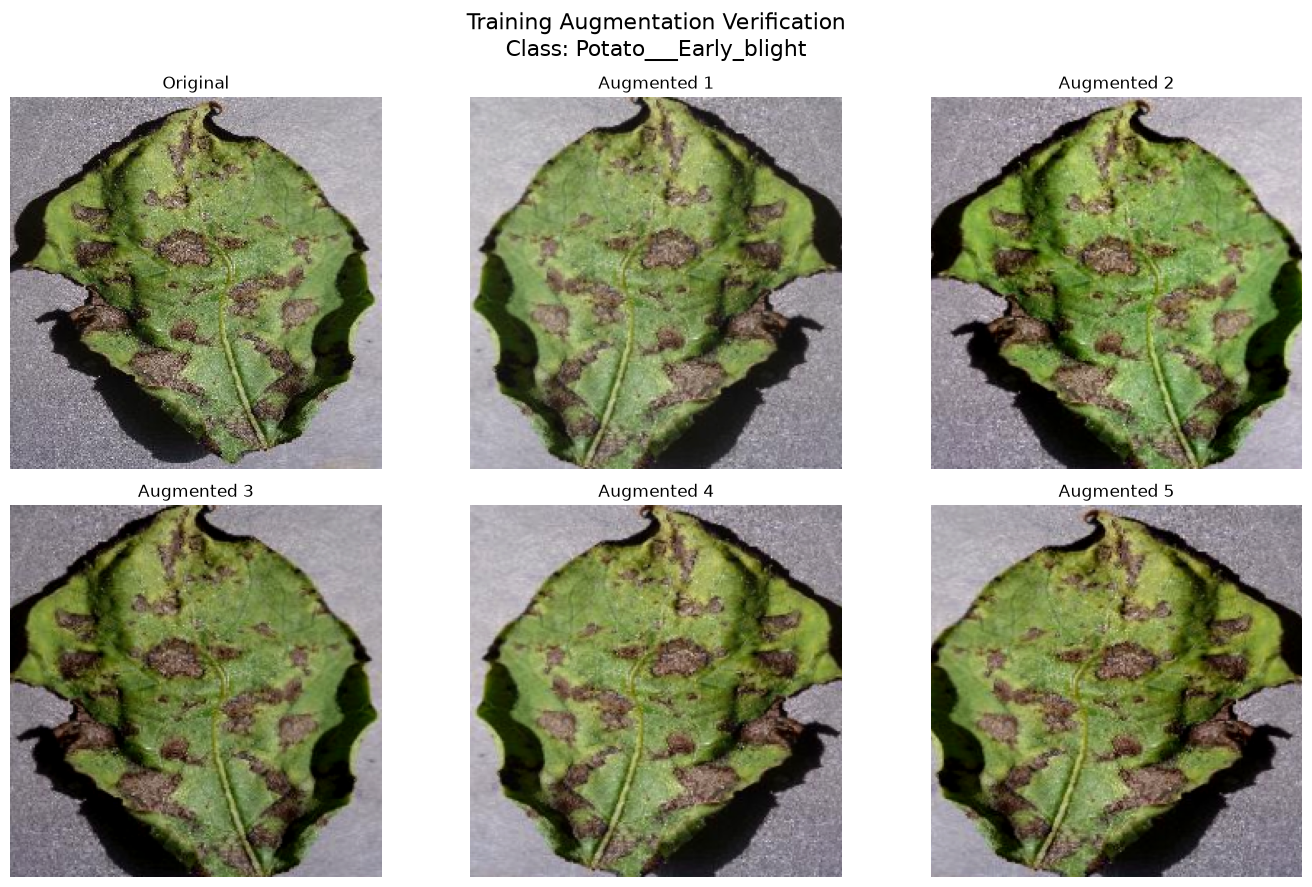

STEP 5.4 STATUS: VISUALIZATION GENERATED


In [11]:
# --------------------------------------------------
# STEP 5.4 — VISUAL AUGMENTATION VERIFICATION
# --------------------------------------------------

import matplotlib.pyplot as plt
from PIL import Image

# Select one original training image
sample_path = sample_images[0]

original_image = Image.open(sample_path).convert("RGB")

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

# Original image
axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

# Generate augmented versions
for i in range(1, 6):

    augmented_tensor = train_transform(original_image)

    # Undo ImageNet normalization for visualization
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    display_tensor = augmented_tensor * std + mean

    # Clip values to valid image range
    display_tensor = torch.clamp(display_tensor, 0, 1)

    # Convert CHW → HWC
    display_image = display_tensor.permute(1, 2, 0).numpy()

    axes[i].imshow(display_image)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.suptitle(
    f"Training Augmentation Verification\n"
    f"Class: {sample_path.parent.name}",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 5.4 STATUS: VISUALIZATION GENERATED")
print("=" * 60)

In [8]:
# --------------------------------------------------
# STEP 5.4A — IMPROVED TRAINING AUGMENTATION
# --------------------------------------------------

train_transform = transforms.Compose([
    
    # Small realistic rotation
    transforms.RandomRotation(
        degrees=15
    ),

    # Crop after rotation to remove empty corners
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.85, 1.0),
        ratio=(0.9, 1.1)
    ),

    # Horizontal orientation variation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Mild lighting/color variation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Improved training augmentation pipeline created.")

print("\nPipeline order:")
print("1. RandomRotation: ±15°")
print("2. RandomResizedCrop: 85–100%")
print("3. RandomHorizontalFlip: p=0.5")
print("4. ColorJitter: mild")
print("5. ToTensor")
print("6. ImageNet normalization")

Improved training augmentation pipeline created.

Pipeline order:
1. RandomRotation: ±15°
2. RandomResizedCrop: 85–100%
3. RandomHorizontalFlip: p=0.5
4. ColorJitter: mild
5. ToTensor
6. ImageNet normalization


In [10]:
# --------------------------------------------------
# STEP 5.4B — FINAL TRAINING AUGMENTATION
# --------------------------------------------------

train_transform = transforms.Compose([

    # Randomly crop and resize the leaf
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.85, 1.0),
        ratio=(0.9, 1.1)
    ),

    # Horizontal orientation variation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Mild lighting and color variation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Final training augmentation pipeline created.")

print("\nPipeline:")
print("1. RandomResizedCrop: 85–100%")
print("2. RandomHorizontalFlip: p=0.5")
print("3. ColorJitter: mild")
print("4. ToTensor")
print("5. ImageNet normalization")

Final training augmentation pipeline created.

Pipeline:
1. RandomResizedCrop: 85–100%
2. RandomHorizontalFlip: p=0.5
3. ColorJitter: mild
4. ToTensor
5. ImageNet normalization


In [12]:
# --------------------------------------------------
# STEP 5.5 — PYTORCH DATASETS AND DATALOADERS
# --------------------------------------------------

import torch
from torchvision import datasets
from torch.utils.data import DataLoader

# --------------------------------------------------
# Configuration
# --------------------------------------------------

BATCH_SIZE = 32

NUM_WORKERS = 0   # Safe setting for Windows/Jupyter

# --------------------------------------------------
# Dataset paths
# --------------------------------------------------

TRAIN_DIR = "data/processed/tomato_potato_split/train"
VAL_DIR = "data/processed/tomato_potato_split/val"
TEST_DIR = "data/processed/tomato_potato_split/test"

# --------------------------------------------------
# Create datasets
# --------------------------------------------------

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=val_test_transform
)

# --------------------------------------------------
# Create DataLoaders
# --------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# --------------------------------------------------
# Display dataset information
# --------------------------------------------------

print("=" * 60)
print("PYTORCH DATASET INFORMATION")
print("=" * 60)

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nNumber of classes:", len(train_dataset.classes))

print("\nClass mapping:")
for index, class_name in enumerate(train_dataset.classes):
    print(f"{index}: {class_name}")

# --------------------------------------------------
# Get one batch
# --------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 60)
print("TRAINING BATCH")
print("=" * 60)

print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

# --------------------------------------------------
# Validate
# --------------------------------------------------

assert len(train_dataset) == 14208
assert len(val_dataset) == 3045
assert len(test_dataset) == 3045

assert len(train_dataset.classes) == 13
assert train_dataset.classes == val_dataset.classes
assert train_dataset.classes == test_dataset.classes

assert images.shape[1:] == (3, 224, 224)
assert labels.shape[0] <= BATCH_SIZE

print("\n" + "=" * 60)
print("STEP 5.5 STATUS: PASSED")
print("=" * 60)

PYTORCH DATASET INFORMATION

Training samples: 14208
Validation samples: 3045
Test samples: 3045

Number of classes: 13

Class mapping:
0: Potato___Early_blight
1: Potato___Late_blight
2: Potato___healthy
3: Tomato___Bacterial_spot
4: Tomato___Early_blight
5: Tomato___Late_blight
6: Tomato___Leaf_Mold
7: Tomato___Septoria_leaf_spot
8: Tomato___Spider_mites Two-spotted_spider_mite
9: Tomato___Target_Spot
10: Tomato___Tomato_Yellow_Leaf_Curl_Virus
11: Tomato___Tomato_mosaic_virus
12: Tomato___healthy

TRAINING BATCH
Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64

STEP 5.5 STATUS: PASSED


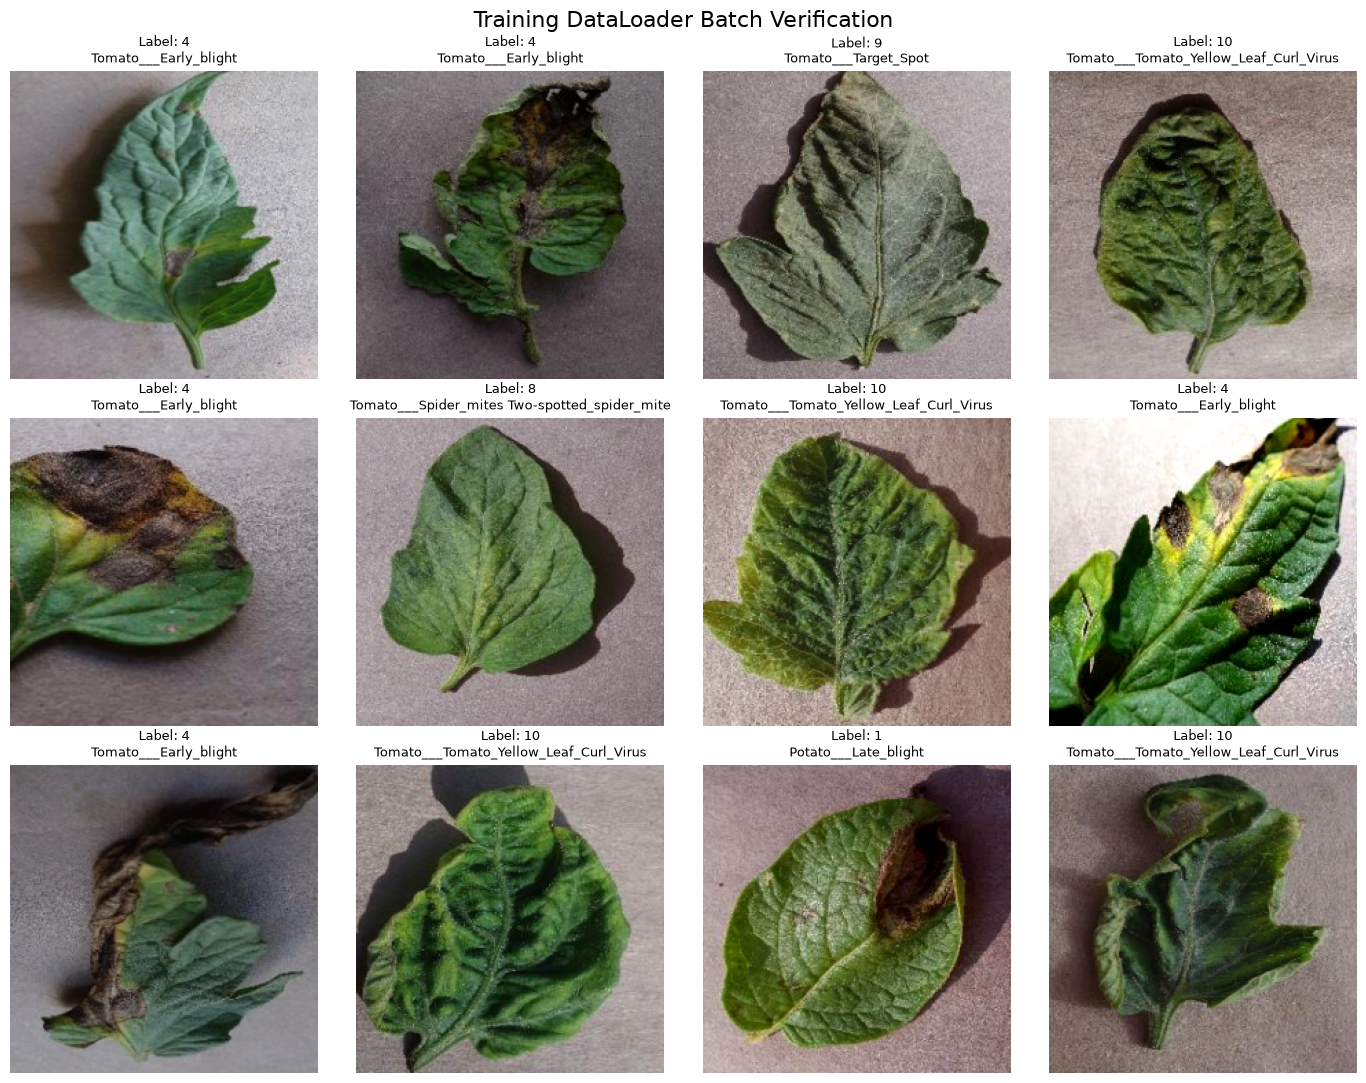

STEP 5.6 STATUS: VISUALIZATION GENERATED


In [13]:
# --------------------------------------------------
# STEP 5.6 — VISUALIZE A TRAINING BATCH
# --------------------------------------------------

import matplotlib.pyplot as plt
import torch

# Get one batch
images, labels = next(iter(train_loader))

# ImageNet mean/std tensors
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

# Create figure
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
axes = axes.flatten()

for i in range(12):

    # Take image from batch
    image = images[i]

    # Undo normalization
    image = image * std + mean

    # Keep values in valid range
    image = torch.clamp(image, 0, 1)

    # Convert CHW → HWC
    image = image.permute(1, 2, 0).numpy()

    # Display
    axes[i].imshow(image)

    class_index = labels[i].item()
    class_name = train_dataset.classes[class_index]

    axes[i].set_title(
        f"Label: {class_index}\n{class_name}",
        fontsize=9
    )

    axes[i].axis("off")

plt.suptitle(
    "Training DataLoader Batch Verification",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 5.6 STATUS: VISUALIZATION GENERATED")
print("=" * 60)